# Setup 

## Random seed for notebook


In [1]:
my_random_seed = 123
my_genotypes_file = "./data_genotypes/vfaba.genotypes.afabae.n6.tsv"
my_phenotypes_file = "../../01.GWAS/01_phenotipic_analysis/02.ajusted_means/fabae/emmeans_fabae_n6_genotypes_and_emmeans.csv"

## Libraries

In [2]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer


# import PCA from sklearn.decomposition import PCA
from sklearn.decomposition import PCA

# Data
1. Genotypes (X matrix): a dataframe with SNPs as rows and individuals as columns.  
2. Phenotypes (y vector): a dataframe with individuals as rows and the BLUEs (estimated genotype values) as the sole column.  

## Genotypes

In [3]:
genotypes_df_snps_in_rows = pd.read_csv(my_genotypes_file, index_col=0, sep="\t")
print("Original shape:", genotypes_df_snps_in_rows.shape)
print("First index values:", genotypes_df_snps_in_rows.index.values[0:3])
genotypes_df_snps_in_rows.iloc[0:5,0:5]

Original shape: (104493, 187)
First index values: ['chr1S_167707' 'chr1S_167764' 'chr1S_173981']


,IVIP100034,IVIP100081,IVIP100121,IVIP100123,IVIP100124
snp_id,,,,,
chr1S_167707,1/1,1/1,1/1,1/1,1/1
chr1S_167764,0/0,0/0,0/0,0/0,0/0
chr1S_173981,0/0,0/0,0/0,0/0,0/0
chr1S_174088,0/0,0/0,0/0,0/0,0/0
chr1S_174404,0/0,0/0,0/0,0/0,0/0


In [16]:
# transpose so that samples are rows and SNPs are columns
genotypes_df = genotypes_df_snps_in_rows.T
print("After conversion shape:", genotypes_df.shape)
genotypes_df.iloc[0:5,0:5]

After conversion shape: (187, 104493)


snp_id,chr1S_167707,chr1S_167764,chr1S_173981,chr1S_174088,chr1S_174404
IVIP100034,1/1,0/0,0/0,0/0,0/0
IVIP100081,1/1,0/0,0/0,0/0,0/0
IVIP100121,1/1,0/0,0/0,0/0,0/0
IVIP100123,1/1,0/0,0/0,0/0,0/0
IVIP100124,1/1,0/0,0/0,0/0,0/0


In [5]:
# Convert genotype calls to additive encoding
# '0/0' -> 0, '0/1' -> 1, '1/1' -> 2
genotype_mapping = {'.': np.nan,
                    './.': np.nan,
                    '.|.': np.nan,
                    '0|0': 0,
                    '0/0': 0, 
                    '0/1': 1, 
                    '0|1': 1, 
                    '1/1': 2, 
                    '1|1': 2}
genotypes_df = genotypes_df.replace(genotype_mapping)
genotypes_df.head(n=3)

/var/folders/1m/y_dgq0b95f7bhj85vsbhgjf40000gn/T/ipykernel_18302/1663100177.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  genotypes_df = genotypes_df.replace(genotype_mapping)


snp_id,chr1S_167707,chr1S_167764,chr1S_173981,chr1S_174088,chr1S_174404,chr1S_174421,chr1S_174692,chr1S_174776,chr1S_174979,chr1S_175082,...,contig_1519_14938,contig_1519_14948,contig_1519_14973,contig_1519_15005,contig_1519_15026,contig_1519_15034,contig_1519_15097,contig_1519_15116,contig_1629_250430,contig_1629_250442
IVIP100034,2,0,0,0,0,0,0,0,0,0,...,0,2,0,0,0,0,0,0,0,0
IVIP100081,2,0,0,0,0,2,0,0,2,0,...,1,1,0,0,2,0,0,0,0,0
IVIP100121,2,0,0,0,0,2,2,0,0,0,...,0,0,0,0,0,0,1,1,0,0


## Phenotypes

In [18]:
phenotypes_df = pd.read_csv(my_phenotypes_file, index_col=0, sep=",")
phenotypes_df.rename(columns={'emmean': 'blues'}, inplace=True)
print("Original dimensions of phenotype file: ", phenotypes_df.shape)
phenotypes_df.head(n=3)

Original dimensions of phenotype file:  (187, 1)


,blues
ivip,
IVIP100034,41.743707
IVIP100081,37.393715
IVIP100121,40.923005


# Dimension reduction of the SNP data

## Create a PCA model

In [7]:
n_individuals = phenotypes_df.shape[0]
n_snps = genotypes_df.shape[1]
my_pca = PCA(n_components=min(n_individuals, n_snps), random_state=my_random_seed)

## Fit a PCA model and extract information (scree plot, variance explained by each component, etc.)

We need to impute missing data before applying PCA. We will use the most frequent genotype for each SNP to fill in missing values.
Note: the `SimpleImputer` class from `sklearn.impute` imputes column-wise, so we can directly apply it to our dataframe where SNPs are columns and individuals are rows.

In [8]:
my_imputer = SimpleImputer(strategy='most_frequent')
genotypes_df_imputed = pd.DataFrame(my_imputer.fit_transform(genotypes_df), 
                                    index=genotypes_df.index, 
                                    columns=genotypes_df.columns)
# count number of missing values in the original and imputed dataframe 
print("Number of missing values in original dataframe:", genotypes_df.isna().sum().sum())
print("Number of missing values in imputed dataframe:", genotypes_df_imputed.isna().sum().sum())

Number of missing values in original dataframe: 0
Number of missing values in imputed dataframe: 0


In [9]:
my_pca.fit(genotypes_df_imputed)

,n_components,187
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,123


In [10]:
def plot_pca_explained_variance(pca_model, n_components=10, figsize=(8, 4)):
    """
    Plot the explained variance ratio for the first N principal components.
    
    Parameters:
    -----------
    pca_model : sklearn.decomposition.PCA
        Fitted PCA model
    n_components : int, default=10
        Number of principal components to plot
    figsize : tuple, default=(8, 4)
        Figure size for the plot
    
    Returns:
    --------
    pandas.DataFrame
        DataFrame with explained variance ratios and PC numbers
    """
    exp_var_df = pd.DataFrame(pca_model.explained_variance_ratio_)
    exp_var_df.columns = ['exp_var_ratio']
    exp_var_df['pc'] = exp_var_df.index + 1
    exp_var_df.set_index('pc', inplace=True)
    
    # Ensure we don't plot more components than available
    n_to_plot = min(n_components, len(exp_var_df))
    
    # Create the plot
    plt.figure(figsize=figsize)
    plt.bar(exp_var_df.index[:n_to_plot], exp_var_df['exp_var_ratio'][:n_to_plot], color='skyblue')
    # Label each x-axis tick with PC number
    plt.xticks(exp_var_df.index[:n_to_plot], [f'PC{i}' for i in exp_var_df.index[:n_to_plot]], rotation=0)
    plt.xlabel('Principal Component', fontsize=10)
    plt.ylabel('Explained Variance Ratio', fontsize=10)
    plt.title(f'PCA Explained Variance Ratio (First {n_to_plot} Components)', fontsize=14)
    plt.tight_layout()
    plt.show()



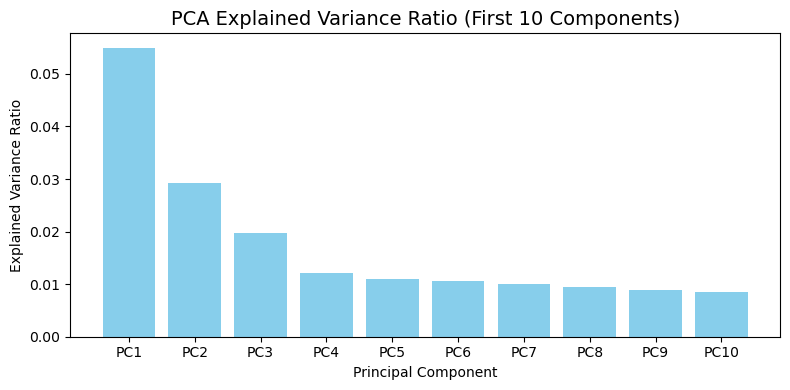

In [11]:
# Use the function to plot the first 10 components
exp_var_df = plot_pca_explained_variance(my_pca, n_components=10)

## Reduce the SNP data using the PCA model

In [12]:
genotypes_reduced = my_pca.fit_transform(genotypes_df_imputed)
genotypes_reduced_df = pd.DataFrame(genotypes_reduced, columns=[f'PC{i+1}' for i in range(my_pca.n_components_)])
# add individuals IDs as index
genotypes_reduced_df.index = genotypes_df.index
print("Reduced shape:", genotypes_reduced.shape)
genotypes_reduced_df.head(n=3)

Reduced shape: (187, 187)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC178,PC179,PC180,PC181,PC182,PC183,PC184,PC185,PC186,PC187
IVIP100034,54.549141,38.133582,142.660935,-49.956386,0.748640,5.414148,10.059607,17.291886,10.684848,-13.075276,...,0.515109,-0.488115,-7.384926,8.736871,-63.275841,-71.029276,-0.929247,0.059199,-0.034280,-3.886158e-13
IVIP100081,-46.480913,-36.233098,5.090303,2.873656,0.927594,-8.819168,27.713060,-26.812522,-73.067061,-21.773864,...,2.870699,-1.161345,0.985076,-95.207466,-7.708934,-3.529448,-0.040486,0.040201,-0.013806,-3.886158e-13
IVIP100121,-45.764929,-32.709310,4.784485,2.183271,-1.832020,-3.176112,11.474953,-3.396201,-9.216511,-1.973546,...,1.263773,0.928534,0.013973,-2.558860,-0.443817,0.194822,-0.054120,-0.003396,0.010738,-3.886158e-13


## Add the phenotypic values to the reduced SNP dataframe

In [13]:
# add the phenotypic values to the reduced SNP dataframe using merge 
df4ml = genotypes_reduced_df.merge(phenotypes_df[['blues']], left_index=True, right_index=True, how='inner')
df4ml.shape


(187, 188)

In [14]:
df4ml.head(n=3)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC179,PC180,PC181,PC182,PC183,PC184,PC185,PC186,PC187,blues
IVIP100034,54.549141,38.133582,142.660935,-49.956386,0.748640,5.414148,10.059607,17.291886,10.684848,-13.075276,...,-0.488115,-7.384926,8.736871,-63.275841,-71.029276,-0.929247,0.059199,-0.034280,-3.886158e-13,41.743707
IVIP100081,-46.480913,-36.233098,5.090303,2.873656,0.927594,-8.819168,27.713060,-26.812522,-73.067061,-21.773864,...,-1.161345,0.985076,-95.207466,-7.708934,-3.529448,-0.040486,0.040201,-0.013806,-3.886158e-13,37.393715
IVIP100121,-45.764929,-32.709310,4.784485,2.183271,-1.832020,-3.176112,11.474953,-3.396201,-9.216511,-1.973546,...,0.928534,0.013973,-2.558860,-0.443817,0.194822,-0.054120,-0.003396,0.010738,-3.886158e-13,40.923005


# Write original and reduced SNP data to file


In [15]:
# write reduced SNP data with phenotypes to file
# add column names
df4ml.to_csv("./ml_ready/genotypes_reduced_and_pheno.tsv", sep="\t", index=True, header=True)